# Model B: MobileNetV2 transfer learning

Binary classification of **Real vs AI-Generated** images with an ImageNet-pretrained MobileNetV2.
Dataset: Defactify Image Dataset (same group-based split and same preprocessing as Model A).
Framework: TensorFlow / Keras. Runs on Colab or Kaggle (auto-detected).

The test split is **not** used in this notebook.

## 1. Environment

In [2]:
!pip -q install datasets huggingface_hub

In [3]:
import os
import io
import json
import shutil
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

# Compatibility shim for loading nested Keras models on some Colab/Kaggle images
if not hasattr(keras, "KerasTensor"):
    from keras.src.backend import KerasTensor
    keras.KerasTensor = KerasTensor

from pathlib import Path
from PIL import Image as PILImage
from datasets import load_dataset
from tensorflow.keras import layers, models

In [4]:
# EXPERIMENT CONFIGURATION  (change only this cell between runs)
MODEL_NAME = "mobilenetv2"  # filename prefix

# Shared data-pipeline switches (identical in Model A and Model B notebooks)
CENTER_CROP = True   # crop to a centered square before resizing (no aspect-ratio distortion)
USE_AUG = True       # training-only augmentation (flip, random crop, JPEG recompression)
JPEG_PROB = 0.5      # probability of JPEG recompression, applied to BOTH classes
JPEG_QUALITY = (60, 95)
CROP_FRACTION = (0.80, 1.00)   # random crop side, as a fraction of the square side

IMAGE_SIZE = 224
IMAGE_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 3)
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

# Model B training
RUN_TUNING = True
TUNE_TRAIN_SIZE = 6000
TUNE_VAL_SIZE = 1500
TUNE_EPOCHS = 2
DEFAULT_CONFIG = {"learning_rate": 1e-3, "dropout": 0.2}
tuning_grid = [
    {"learning_rate": 1e-3, "dropout": 0.2},
    {"learning_rate": 1e-3, "dropout": 0.4},
    {"learning_rate": 3e-4, "dropout": 0.2},
    {"learning_rate": 3e-4, "dropout": 0.4},
]
STAGE1_EPOCHS = 8
STAGE1_ES_PATIENCE = 3
FINE_TUNE_LAYERS = 20
FINE_TUNE_LR = 5e-6
STAGE2_EPOCHS = 10
STAGE2_ES_PATIENCE = 2

DATASET_ID = "Rajarshi-Roy-research/Defactify_Image_Dataset"
# Pinned dataset commit (the manifest in the repo still says "main")
HF_REVISION_FALLBACK = "1c3b714c9691eb6dd11c2c1e92eab1ac29584fa0"

REPO_URL = "https://github.com/Michaelatj/AI-Generated-Image-Classification-using-CNN.git"
GIT_USER_NAME = "Michael Andreas Tjendra"
GIT_USER_EMAIL = "alongbest2000@gmail.com"
GITHUB_USERNAME = "Michaelatj"

# Environment detection (Kaggle or Colab)
IN_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IN_KAGGLE else Path("/content")
HF_CACHE_DIR = "/kaggle/temp/huggingface_cache" if IN_KAGGLE else "/content/huggingface_cache"
REPO_DIR = WORK_DIR / "AI-Generated-Image-Classification-using-CNN"

print("Environment:", "Kaggle" if IN_KAGGLE else "Colab/other")
print("CENTER_CROP:", CENTER_CROP, "| USE_AUG:", USE_AUG)

Environment: Colab/other
CENTER_CROP: True | USE_AUG: True


In [5]:
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

os.chdir(REPO_DIR)

status = subprocess.check_output(["git", "status", "--porcelain"], text=True)
if status.strip():
    raise RuntimeError("Repository contains local changes. Check git status before syncing.")

subprocess.run(["git", "pull", "--rebase", "origin", "main"], check=True)
print(subprocess.check_output(["git", "log", "--oneline", "-n", "5"], text=True))

ARTIFACT_DIR = REPO_DIR / "artifacts"
SPLIT_DIR = ARTIFACT_DIR / "splits"
CONFIG_DIR = ARTIFACT_DIR / "configs"
MODEL_DIR = ARTIFACT_DIR / "models"
EVAL_DIR = ARTIFACT_DIR / "evaluation"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

print("Splits:", sorted(p.name for p in SPLIT_DIR.glob("*")))

aa578fa update model b notebook
d904ce9 update model b notebook
a531386 organizing files
634498d Add
b7f2ad2 Merge branch 'main' of https://github.com/Michaelatj/AI-Generated-Image-Classification-using-CNN

Splits: ['test.csv', 'train.csv', 'validation.csv']


In [6]:
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print(error)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Available GPU:", gpus)
if not gpus:
    print("WARNING: no GPU found. Enable a GPU accelerator before training.")

total, used, free = shutil.disk_usage(str(WORK_DIR))
print(f"Free storage: {free / (1024**3):.2f} GB")

TensorFlow: 2.21.0
Keras: 3.13.2
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Free storage: 112.40 GB


## 2. Dataset and split verification
Loads the shared manifests, then verifies before any training: no caption-group overlap, no row used twice, and manifest labels/captions equal the original Hugging Face rows.

In [7]:
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

# Same ordering rule for every split, so prediction order always matches the dataframe
sort_cols = ["source_split", "row_idx"]
train_df = train_df.sort_values(sort_cols).reset_index(drop=True)
val_df = val_df.sort_values(sort_cols).reset_index(drop=True)
test_df = test_df.sort_values(sort_cols).reset_index(drop=True)

SPLITS = {"train": train_df, "validation": val_df, "test": test_df}

for name, df in SPLITS.items():
    print(f"{name}: {df.shape} | class share:",
          df["label_a"].value_counts(normalize=True).round(3).to_dict())

# ---- leakage checks -------------------------------------------------------
groups = {n: set(df["caption_group_id"].dropna()) for n, df in SPLITS.items()}
keys = {n: set(zip(df["source_split"], df["row_idx"])) for n, df in SPLITS.items()}

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert not (groups[a] & groups[b]), f"LEAKAGE: {a} and {b} share caption groups"
    assert not (keys[a] & keys[b]), f"Same source row in {a} and {b}"
    print(f"{a} vs {b}: caption-group overlap = 0, row overlap = 0")

for name, df in SPLITS.items():
    assert df["image_id"].is_unique, f"duplicate image_id in {name}"
    assert not df[sort_cols].duplicated().any(), f"duplicate source rows in {name}"
    assert set(df["label_a"].unique()).issubset({0, 1})
print("Split checks passed.")

train: (42018, 10) | class share: {1: 0.833, 0: 0.167}
validation: (8994, 10) | class share: {1: 0.833, 0: 0.167}
test: (44988, 10) | class share: {1: 0.833, 0: 0.167}
train vs validation: caption-group overlap = 0, row overlap = 0
train vs test: caption-group overlap = 0, row overlap = 0
validation vs test: caption-group overlap = 0, row overlap = 0
Split checks passed.


In [8]:
manifest_path = CONFIG_DIR / "dataset_manifest.json"
HF_REVISION = None
if manifest_path.exists():
    HF_REVISION = json.load(open(manifest_path, encoding="utf-8")).get("dataset_revision")
if not HF_REVISION or HF_REVISION == "main":
    HF_REVISION = HF_REVISION_FALLBACK
print("Dataset revision:", HF_REVISION)

HF_DATASETS = {}
# Only splits that training/validation need. The test split is NOT touched here.
required_splits = sorted(set(train_df["source_split"]) | set(val_df["source_split"]))
for split_name in required_splits:
    HF_DATASETS[split_name] = load_dataset(
        DATASET_ID, split=split_name, revision=HF_REVISION, cache_dir=HF_CACHE_DIR
    )
    print(f"{split_name}: {len(HF_DATASETS[split_name]):,} images")


def normalize_caption(text):
    return " ".join(str(text).strip().split()).casefold()


def validate_mapping(df, split_name):
    for source_split, group in df.groupby("source_split", sort=False):
        hf = HF_DATASETS[source_split]
        idx = group["row_idx"].astype(int).tolist()
        assert min(idx) >= 0 and max(idx) < len(hf), f"Invalid row_idx in {split_name}"
        selected = hf.select(idx)   # does not decode the images
        assert np.array_equal(np.asarray(selected["Label_A"]), group["label_a"].to_numpy()), f"Label_A mismatch: {split_name}"
        assert np.array_equal(np.asarray(selected["Label_B"]), group["label_b"].to_numpy()), f"Label_B mismatch: {split_name}"
        assert [normalize_caption(x) for x in selected["Caption"]] == [normalize_caption(x) for x in group["caption"]], f"Caption mismatch: {split_name}"
    print(f"{split_name}: manifest rows match Hugging Face rows")


validate_mapping(train_df, "train")
validate_mapping(val_df, "validation")

Dataset revision: 1c3b714c9691eb6dd11c2c1e92eab1ac29584fa0


README.md:   0%|          | 0.00/5.37k [00:00<?, ?B/s]

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  333MB            

data/validation-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  345MB            

data/validation-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (30 outputs left out)

Generating validation split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/42000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/45000 [00:00<?, ? examples/s]

test: 45,000 images
train: 42,000 images
validation: 9,000 images
train: manifest rows match Hugging Face rows
validation: manifest rows match Hugging Face rows


## 3. Preprocessing and data pipeline
Identical to Model A. Images are fetched by `source_split` + `row_idx`.

In [9]:
# ----------------------------------------------------------------------------
# Shared preprocessing.  The deployed app MUST apply exactly prepare_image(..., training=False).
# ----------------------------------------------------------------------------
class_counts = train_df["label_a"].value_counts().reindex([0, 1], fill_value=0)
if (class_counts == 0).any():
    raise ValueError("A training class is missing!")
class_weights = {int(l): float(len(train_df) / (2 * class_counts[l])) for l in [0, 1]}
print("Class counts:", class_counts.to_dict())
print("Class weights:", class_weights)


def center_square(image):
    w, h = image.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return image.crop((left, top, left + s, top + s))


def augment(image, rng):
    """Training-only. Applied identically to Real and AI-Generated images."""
    if rng.random() < 0.5:
        image = image.transpose(PILImage.Transpose.FLIP_LEFT_RIGHT)

    w, h = image.size
    frac = rng.uniform(*CROP_FRACTION)
    cw, ch = max(1, int(w * frac)), max(1, int(h * frac))
    left = int(rng.integers(0, w - cw + 1))
    top = int(rng.integers(0, h - ch + 1))
    image = image.crop((left, top, left + cw, top + ch))

    # JPEG recompression: removes the "PNG vs JPEG" and compression-history shortcut
    if rng.random() < JPEG_PROB:
        quality = int(rng.integers(JPEG_QUALITY[0], JPEG_QUALITY[1] + 1))
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)
        image = PILImage.open(buffer).convert("RGB")
    return image


def prepare_image(image, training=False, rng=None):
    image = image.convert("RGB")
    if CENTER_CROP:
        image = center_square(image)
    if training and USE_AUG:
        image = augment(image, rng)
    return image.resize((IMAGE_SIZE, IMAGE_SIZE), resample=PILImage.Resampling.BILINEAR)


def make_generator(df, training, seed):
    rng = np.random.default_rng(seed)

    def gen():
        # full permutation of the training rows on every pass
        d = df.iloc[rng.permutation(len(df))].reset_index(drop=True) if training else df
        for row in d.itertuples(index=False):
            image = HF_DATASETS[row.source_split][int(row.row_idx)]["Image"]
            if image is None:
                raise ValueError(f"Missing image: {row.image_id}")
            arr = np.asarray(prepare_image(image, training, rng), dtype=np.uint8)
            label = np.array([int(row.label_a)], dtype=np.float32)
            weight = np.float32(class_weights[int(row.label_a)] if training else 1.0)
            yield arr, label, weight

    return gen


OUTPUT_SIGNATURE = (
    tf.TensorSpec(shape=IMAGE_SHAPE, dtype=tf.uint8),
    tf.TensorSpec(shape=(1,), dtype=tf.float32),
    tf.TensorSpec(shape=(), dtype=tf.float32),
)


def create_tf_dataset(df, training=False, seed=SEED, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_generator(
        make_generator(df, training, seed), output_signature=OUTPUT_SIGNATURE
    )
    ds = ds.apply(tf.data.experimental.assert_cardinality(len(df)))
    return ds.batch(batch_size).prefetch(AUTOTUNE)


train_dataset = create_tf_dataset(train_df, training=True)
val_dataset = create_tf_dataset(val_df, training=False)

images, labels, weights = next(iter(train_dataset))
print("Batch:", images.shape, images.dtype, "| labels:", labels.shape, "| weights:", weights.shape)

Class counts: {0: 7003, 1: 35015}
Class weights: {0: 3.0, 1: 0.6}
Batch: (32, 224, 224, 3) <dtype: 'uint8'> | labels: (32, 1) | weights: (32,)


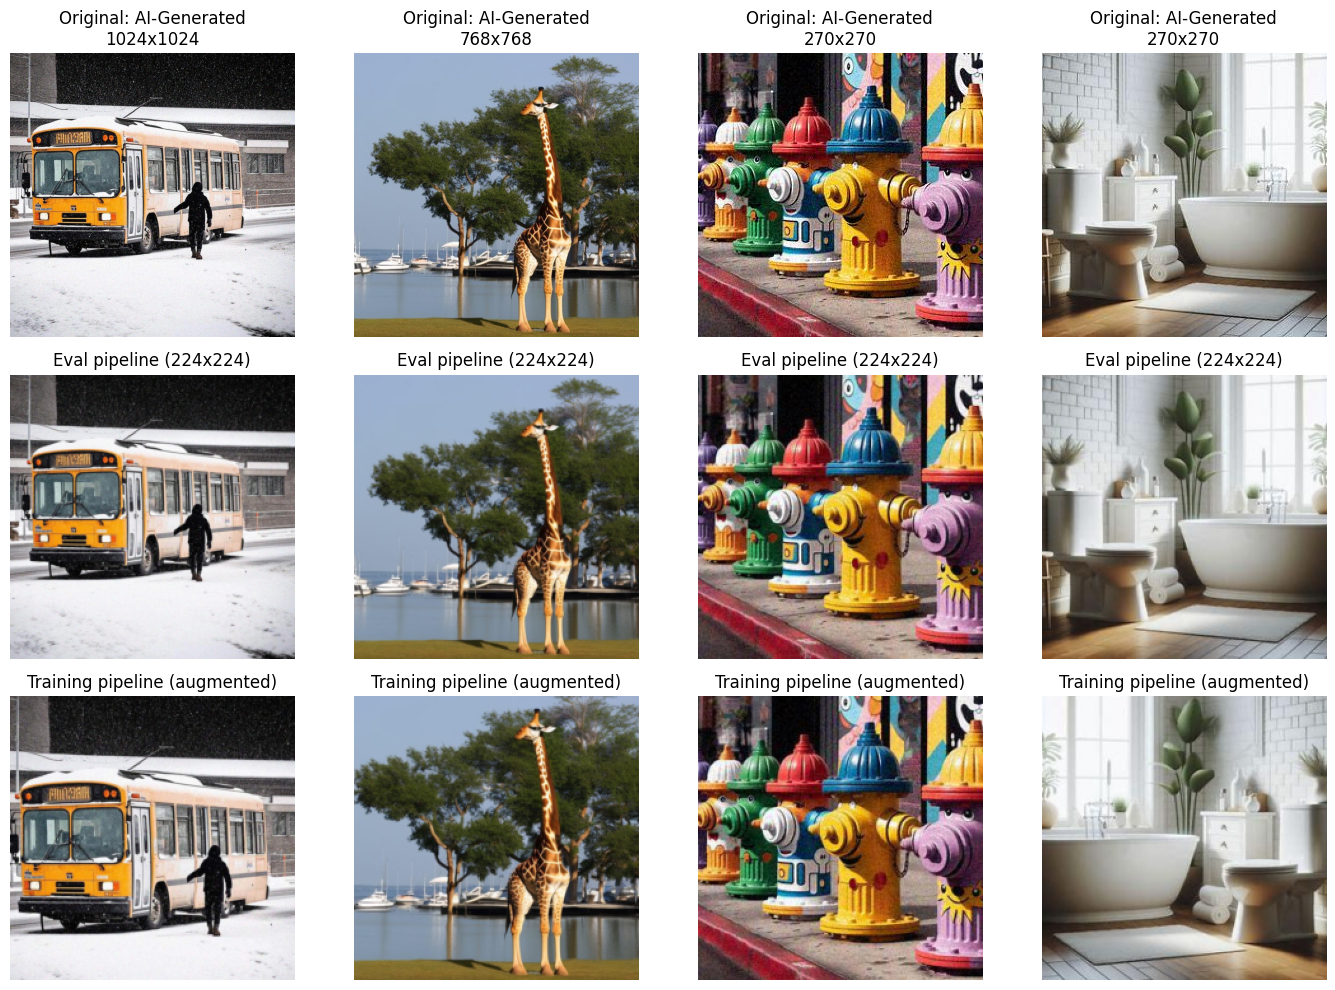

In [10]:
# Visual check of the pipeline (use these figures in the report: preprocessing + augmentation)
rng_vis = np.random.default_rng(0)
rows = train_df.sample(n=4, random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for j, (_, row) in enumerate(rows.iterrows()):
    img = HF_DATASETS[row["source_split"]][int(row["row_idx"])]["Image"].convert("RGB")
    name = "Real" if row["label_a"] == 0 else "AI-Generated"
    axes[0, j].imshow(img)
    axes[0, j].set_title(f"Original: {name}\n{img.size[0]}x{img.size[1]}")
    axes[1, j].imshow(prepare_image(img, training=False))
    axes[1, j].set_title("Eval pipeline (224x224)")
    axes[2, j].imshow(prepare_image(img, training=True, rng=rng_vis))
    axes[2, j].set_title("Training pipeline (augmented)")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(EVAL_DIR / f"{MODEL_NAME}_pipeline_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Model architecture
Raw 0-255 RGB -> MobileNetV2Preprocess ([-1, 1]) -> MobileNetV2 backbone (ImageNet) -> GlobalAveragePooling -> Dropout -> Dense(1, sigmoid = P(AI-Generated)).

In [11]:
@keras.saving.register_keras_serializable(package="aigen")
class MobileNetV2Preprocess(layers.Layer):
    """[0, 255] -> [-1, 1]; same as mobilenet_v2.preprocess_input.
    Needed (with the same class definition) whenever this model is loaded."""
    def call(self, x):
        return tf.cast(x, tf.float32) / 127.5 - 1.0


def build_model(dropout=0.3):
    inputs = layers.Input(shape=IMAGE_SHAPE, name="image")
    x = MobileNetV2Preprocess(name="mobilenetv2_preprocess")(inputs)
    base = tf.keras.applications.MobileNetV2(
        input_shape=IMAGE_SHAPE, include_top=False, weights="imagenet")
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="head_dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)
    return models.Model(inputs, outputs, name="MobileNetV2_Transfer")


model = build_model()
model.summary()
print("Trainable (stage 1):", sum(int(np.prod(w.shape)) for w in model.trainable_weights),
      "/ total:", model.count_params())

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocess          │ (None, 224, 224, 3)    │             0 │
│ (MobileNetV2Preprocess)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable (stage 1): 1281 / total: 2259265


In [12]:
def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc"),
        ],
    )
    return model

## Hyperparameter tuning (stage 1, small subset)
Chooses the head learning rate and dropout with the backbone frozen.

In [13]:
tuning_df = pd.DataFrame()
best_config = dict(DEFAULT_CONFIG)

if RUN_TUNING:
    # Small random subsets taken from their own splits (no leakage)
    tune_train = (train_df.sample(n=min(TUNE_TRAIN_SIZE, len(train_df)), random_state=SEED)
                  .sort_values(sort_cols).reset_index(drop=True))
    tune_val = (val_df.sample(n=min(TUNE_VAL_SIZE, len(val_df)), random_state=SEED)
                .sort_values(sort_cols).reset_index(drop=True))
    tune_train_ds = create_tf_dataset(tune_train, training=True)
    tune_val_ds = create_tf_dataset(tune_val, training=False)

    rows = []
    for cfg in tuning_grid:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        m = compile_model(build_model(cfg["dropout"]), cfg["learning_rate"])
        h = m.fit(tune_train_ds, validation_data=tune_val_ds, epochs=TUNE_EPOCHS, verbose=0)
        i = int(np.argmin(h.history["val_loss"]))
        rows.append({**cfg,
                     "best_val_loss": h.history["val_loss"][i],
                     "val_accuracy": h.history["val_accuracy"][i],
                     "val_auc": h.history["val_auc"][i]})
        print(rows[-1])

    tuning_df = pd.DataFrame(rows).sort_values("best_val_loss").reset_index(drop=True)
    display(tuning_df)
    best_config = {"learning_rate": float(tuning_df.loc[0, "learning_rate"]),
                   "dropout": float(tuning_df.loc[0, "dropout"])}

print("Selected config:", best_config)

{'learning_rate': 0.001, 'dropout': 0.2, 'best_val_loss': 0.40833720564842224, 'val_accuracy': 0.8273333311080933, 'val_auc': 0.8607543706893921}
{'learning_rate': 0.001, 'dropout': 0.4, 'best_val_loss': 0.41103750467300415, 'val_accuracy': 0.8226666450500488, 'val_auc': 0.8545428514480591}
{'learning_rate': 0.0003, 'dropout': 0.2, 'best_val_loss': 0.6124898791313171, 'val_accuracy': 0.659333348274231, 'val_auc': 0.6827797889709473}
{'learning_rate': 0.0003, 'dropout': 0.4, 'best_val_loss': 0.6268335580825806, 'val_accuracy': 0.6520000100135803, 'val_auc': 0.7684227824211121}


,learning_rate,dropout,best_val_loss,val_accuracy,val_auc
0,0.0010,0.2,0.408337,0.827333,0.860754
1,0.0010,0.4,0.411038,0.822667,0.854543
2,0.0003,0.2,0.612490,0.659333,0.682780
3,0.0003,0.4,0.626834,0.652000,0.768423


Selected config: {'learning_rate': 0.001, 'dropout': 0.2}


## Stage 1: frozen backbone
Only the new classification head is trained; all MobileNetV2 weights stay at their ImageNet values.

In [14]:
STAGE1_PATH = MODEL_DIR / f"{MODEL_NAME}_stage1_best.keras"
STAGE2_PATH = MODEL_DIR / f"{MODEL_NAME}_stage2_best.keras"
BEST_MODEL_PATH = MODEL_DIR / f"{MODEL_NAME}_best.keras"
HISTORY_PATH = MODEL_DIR / f"{MODEL_NAME}_history.csv"


def make_callbacks(path, patience, min_lr):
    return [
        tf.keras.callbacks.ModelCheckpoint(str(path), monitor="val_loss", mode="min",
                                           save_best_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                         restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1,
                                             min_lr=min_lr, verbose=1),
    ]


tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

model = build_model(best_config["dropout"])
compile_model(model, best_config["learning_rate"])

history_s1 = model.fit(train_dataset, validation_data=val_dataset, epochs=STAGE1_EPOCHS,
                       callbacks=make_callbacks(STAGE1_PATH, STAGE1_ES_PATIENCE, 1e-6), verbose=1)
print("Stage 1 completed. Epochs run:", len(history_s1.epoch))

Epoch 1/8
1314/1314 ━━━━━━━━━━━━━━━━━━━━ 0s 491ms/step - accuracy: 0.6985 - auc: 0.7762 - loss: 0.5631 - precision: 0.9215 - recall: 0.6939
Epoch 1: val_loss improved from None to 0.42944, saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage1_best.keras

Epoch 1: finished saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage1_best.keras
1314/1314 ━━━━━━━━━━━━━━━━━━━━ 757s 570ms/step - accuracy: 0.7570 - auc: 0.8419 - loss: 0.4907 - precision: 0.9413 - recall: 0.7555 - val_accuracy: 0.8082 - val_auc: 0.8923 - val_loss: 0.4294 - val_precision: 0.9550 - val_recall: 0.8079 - learning_rate: 0.0010
Epoch 2/8
1313/1314 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.7972 - auc: 0.8831 - loss: 0.4335 - precision: 0.9509 - recall: 0.7966
Epoch 2: val_loss improved from 0.42944 to 0.35684, saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage1_be

## Stage 2: fine-tune the last backbone layers
Unfreezes the last `FINE_TUNE_LAYERS` layers of the backbone with a much lower learning rate. BatchNorm layers stay frozen. The previous run overfit here (validation loss was lowest after the first fine-tuning epoch), so fewer layers and a lower learning rate are used.

In [15]:
base_model = next(l for l in model.layers if isinstance(l, keras.Model))
print("Backbone layer:", base_model.name)

base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Unfrozen backbone layers: {FINE_TUNE_LAYERS} | trainable params: {n_trainable:,}")

compile_model(model, FINE_TUNE_LR)   # recompile after changing `trainable`

history_s2 = model.fit(train_dataset, validation_data=val_dataset, epochs=STAGE2_EPOCHS,
                       callbacks=make_callbacks(STAGE2_PATH, STAGE2_ES_PATIENCE, 1e-7), verbose=1)
print("Stage 2 completed. Epochs run:", len(history_s2.epoch))

Backbone layer: mobilenetv2_1.00_224
Unfrozen backbone layers: 20 | trainable params: 1,196,161
Epoch 1/10
1314/1314 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - accuracy: 0.8222 - auc: 0.9056 - loss: 0.3873 - precision: 0.9579 - recall: 0.8230
Epoch 1: val_loss improved from None to 0.33413, saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage2_best.keras

Epoch 1: finished saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage2_best.keras
1314/1314 ━━━━━━━━━━━━━━━━━━━━ 743s 555ms/step - accuracy: 0.8329 - auc: 0.9145 - loss: 0.3711 - precision: 0.9619 - recall: 0.8325 - val_accuracy: 0.8560 - val_auc: 0.9240 - val_loss: 0.3341 - val_precision: 0.9598 - val_recall: 0.8634 - learning_rate: 5.0000e-06
Epoch 2/10
1313/1314 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step - accuracy: 0.8637 - auc: 0.9374 - loss: 0.3190 - precision: 0.9701 - recall: 0.8632
Epoch 2: val_loss did not improve from 0.33413

Epoch 2: 

## Best-stage selection (validation loss only)

In [16]:
candidates = {}
for name, path in [("stage1_frozen", STAGE1_PATH), ("stage2_finetune", STAGE2_PATH)]:
    if path.exists():
        m = tf.keras.models.load_model(path)
        res = m.evaluate(val_dataset, return_dict=True, verbose=0)
        candidates[name] = {"path": path, **res}
        print(name, {k: round(v, 4) for k, v in res.items() if k != "path"})

assert candidates, "No checkpoint was saved."
best_name = min(candidates, key=lambda k: candidates[k]["loss"])
shutil.copyfile(candidates[best_name]["path"], BEST_MODEL_PATH)
print("\nBest stage:", best_name, "->", BEST_MODEL_PATH.name)

stage1_frozen {'accuracy': 0.8492, 'auc': 0.8961, 'loss': 0.3568, 'precision': 0.9462, 'recall': 0.8684}
stage2_finetune {'accuracy': 0.9012, 'auc': 0.95, 'loss': 0.2436, 'precision': 0.9634, 'recall': 0.9162}

Best stage: stage2_finetune -> mobilenetv2_best.keras


In [17]:
# Stage comparison
stage_comparison = pd.DataFrame(
    [{"stage": k, **{m: v[m] for m in ["loss", "accuracy", "precision", "recall", "auc"]}}
     for k, v in candidates.items()])
display(stage_comparison)

,stage,loss,accuracy,precision,recall,auc
0,stage1_frozen,0.356842,0.849233,0.946213,0.868446,0.896070
1,stage2_finetune,0.243581,0.901156,0.963384,0.916211,0.949984


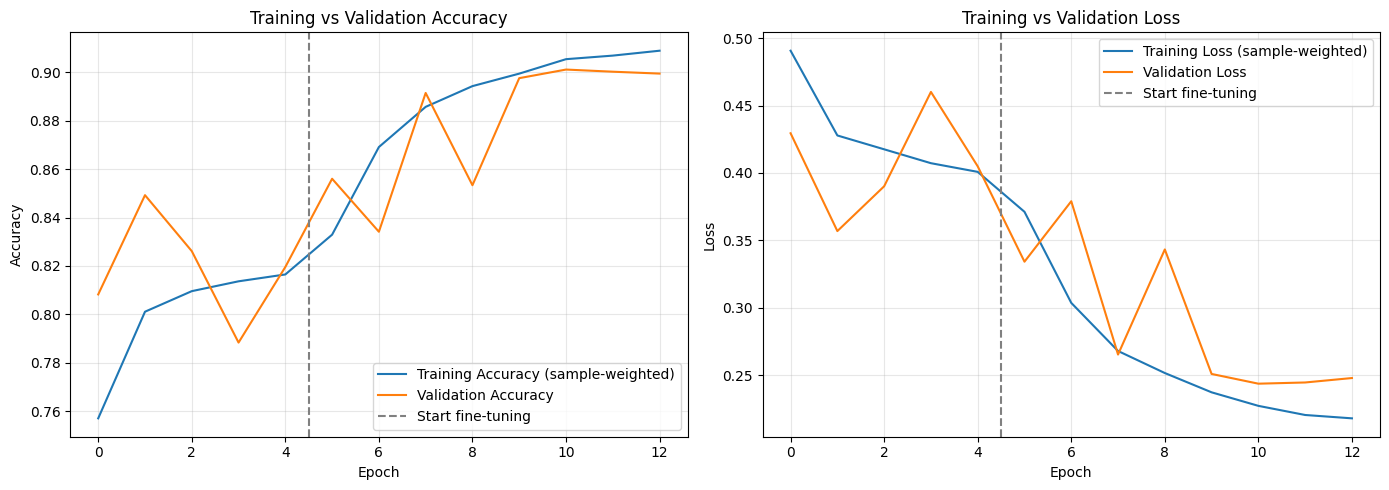

,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall,learning_rate,stage
epoch,,,,,,,,,,,,
0,0.756985,0.841897,0.490703,0.941289,0.755505,0.808205,0.892266,0.429436,0.955047,0.807872,1.000000e-03,frozen
1,0.801061,0.884714,0.427802,0.953488,0.800314,0.849233,0.896070,0.356842,0.946213,0.868446,1.000000e-03,frozen
2,0.809558,0.890869,0.417532,0.954749,0.809853,0.826106,0.895539,0.390092,0.949522,0.835757,1.000000e-03,frozen
3,0.813627,0.896228,0.407224,0.956690,0.813166,0.788303,0.897894,0.460119,0.961532,0.777051,5.000000e-04,frozen
4,0.816460,0.899775,0.400787,0.958058,0.815451,0.819546,0.901644,0.404900,0.957178,0.820147,2.500000e-04,frozen
5,0.832905,0.914528,0.371144,0.961886,0.832472,0.856015,0.923983,0.334125,0.959804,0.863376,5.000000e-06,fine_tune
6,0.869128,0.943741,0.303550,0.971622,0.868314,0.834112,0.938674,0.378986,0.975447,0.821614,5.000000e-06,fine_tune
7,0.885739,0.956433,0.267844,0.976561,0.884107,0.891483,0.943987,0.265206,0.962931,0.904603,2.500000e-06,fine_tune
8,0.894307,0.961483,0.251490,0.978077,0.893189,0.853347,0.946934,0.343206,0.976985,0.843896,2.500000e-06,fine_tune


In [18]:
h1 = pd.DataFrame(history_s1.history); h1["stage"] = "frozen"
h2 = pd.DataFrame(history_s2.history); h2["stage"] = "fine_tune"
history_df = pd.concat([h1, h2], ignore_index=True)
history_df.index.name = "epoch"
history_df.to_csv(HISTORY_PATH)

split_at = len(h1) - 0.5
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (tr, va, title) in zip(axes, [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")]):
    ax.plot(history_df[tr].values, label=f"Training {title} (sample-weighted)")
    ax.plot(history_df[va].values, label=f"Validation {title}")
    ax.axvline(split_at, color="gray", linestyle="--", label="Start fine-tuning")
    ax.set_title(f"Training vs Validation {title}")
    ax.set_xlabel("Epoch"); ax.set_ylabel(title); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
CURVES_PATH = EVAL_DIR / f"{MODEL_NAME}_training_curves.png"
plt.savefig(CURVES_PATH, dpi=150, bbox_inches="tight")
plt.show()
display(history_df)

## Validation evaluation
Same function and same threshold rule as Model A (max macro-F1 on validation), so the two models can be compared fairly in `final_testing_comparison`.

In [19]:
# Import evaluation metrics
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
# Load model and generate predictions
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

keras_metrics = best_model.evaluate(
    val_dataset, return_dict=True, verbose=1
)

y_true = val_df["label_a"].to_numpy().astype(int)
y_prob = best_model.predict(
    val_dataset.map(lambda i, l, w: i), verbose=1
).ravel()

assert len(y_prob) == len(y_true)

print("Validation predictions completed.")
print("Number of predictions:", len(y_prob))

282/282 ━━━━━━━━━━━━━━━━━━━━ 102s 343ms/step - accuracy: 0.9012 - auc: 0.9500 - loss: 0.2436 - precision: 0.9634 - recall: 0.9162
282/282 ━━━━━━━━━━━━━━━━━━━━ 96s 324ms/step
Validation predictions completed.
Number of predictions: 8994


In [20]:
# Find optimal threshold
thresholds = np.arange(0.05, 0.96, 0.01)

f1s = [
    f1_score(y_true, (y_prob >= t).astype(int),
             average="macro", zero_division=0)
    for t in thresholds
]

best_threshold = float(thresholds[int(np.argmax(f1s))])

print("Best threshold:", round(best_threshold, 2))
print("Best Macro-F1:", round(max(f1s), 4))

Best threshold: 0.29
Best Macro-F1: 0.8485


In [21]:
# Calculate validation metrics
def summarize(t):
    p = (y_prob >= t).astype(int)
    return {
        "threshold": round(float(t), 2),
        "accuracy": float(accuracy_score(y_true, p)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, p)),
        "precision_ai": float(precision_score(y_true, p, zero_division=0)),
        "recall_ai": float(recall_score(y_true, p, zero_division=0)),
        "recall_real": float(recall_score(y_true, p, pos_label=0, zero_division=0)),
        "f1_ai": float(f1_score(y_true, p, zero_division=0)),
        "f1_macro": float(f1_score(y_true, p, average="macro", zero_division=0)),
        "confusion_matrix": confusion_matrix(y_true, p, labels=[0, 1]).tolist(),
    }

metrics = {
    "keras_evaluate": {k: float(v) for k, v in keras_metrics.items()},
    "roc_auc": float(roc_auc_score(y_true, y_prob)),
    "at_threshold_0.50": summarize(0.5),
    "at_tuned_threshold": summarize(best_threshold),
    "tuned_threshold": round(best_threshold, 2),
    "threshold_selection": "max macro-F1 on validation set",
}

In [22]:
# Validation results summary
summary_df = pd.DataFrame([
    {"evaluation": "Default (0.50)", **metrics["at_threshold_0.50"]},
    {"evaluation": "Tuned", **metrics["at_tuned_threshold"]}
]).drop(columns=["confusion_matrix"])

print("VALIDATION RESULTS | ROC-AUC:", round(metrics["roc_auc"], 4))
print("Selected threshold:", metrics["tuned_threshold"])
display(summary_df.set_index("evaluation"))

VALIDATION RESULTS | ROC-AUC: 0.9501
Selected threshold: 0.29


,threshold,accuracy,balanced_accuracy,precision_ai,recall_ai,recall_real,f1_ai,f1_macro
evaluation,,,,,,,,
Default (0.50),0.50,0.901156,0.871047,0.963384,0.916211,0.825884,0.939205,0.837508
Tuned,0.29,0.918390,0.838159,0.944393,0.958506,0.717812,0.951397,0.848533


In [23]:
# Classification report
y_pred = (y_prob >= best_threshold).astype(int)

report_df = pd.DataFrame(classification_report(
    y_true, y_pred, labels=[0, 1],
    target_names=["Real", "AI-Generated"],
    output_dict=True, zero_division=0
)).transpose()

display(report_df)

,precision,recall,f1-score,support
Real,0.775775,0.717812,0.745669,1499.00000
AI-Generated,0.944393,0.958506,0.951397,7495.00000
accuracy,0.918390,0.918390,0.918390,0.91839
macro avg,0.860084,0.838159,0.848533,8994.00000
weighted avg,0.916290,0.918390,0.917109,8994.00000


In [24]:
# Accuracy per generator
tmp = val_df.assign(pred=y_pred)

per_gen = pd.DataFrame([
    {"label_b_name": name, "images": len(g),
     "accuracy": float((g["pred"] == g["label_a"]).mean())}
    for name, g in tmp.groupby("label_b_name")
])

display(per_gen)

,label_b_name,images,accuracy
0,DALL-E 3,1499,0.978652
1,Midjourney v6,1499,0.959973
2,Real,1499,0.717812
3,Stable Diffusion 2.1,1499,0.949967
4,Stable Diffusion 3,1499,0.943296
5,Stable Diffusion XL (SDXL),1499,0.960640


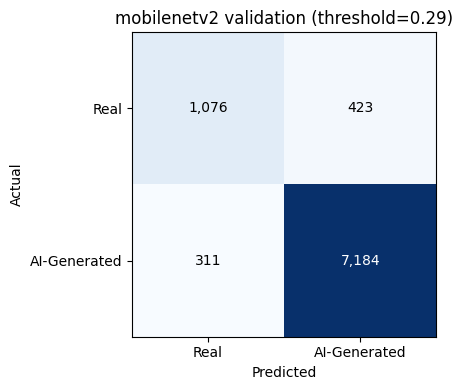

In [25]:
# Confusion matrix
cm = np.array(metrics["at_tuned_threshold"]["confusion_matrix"])

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Real", "AI-Generated"])
ax.set_yticklabels(["Real", "AI-Generated"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"{MODEL_NAME} validation (threshold={best_threshold:.2f})")

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.savefig(EVAL_DIR / f"{MODEL_NAME}_confusion_matrix.png",
            dpi=150, bbox_inches="tight")
plt.show()

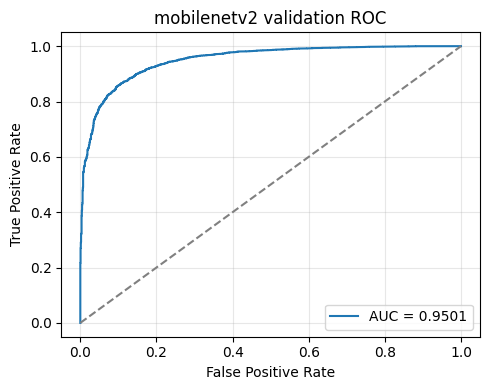

In [26]:
# ROC curve
fpr, tpr, _ = roc_curve(y_true, y_prob)

plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {metrics['roc_auc']:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"{MODEL_NAME} validation ROC")
plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(EVAL_DIR / f"{MODEL_NAME}_roc_curve.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [34]:
# Save evaluation artifacts
PREFIX = MODEL_NAME

paths = {
    "metrics": EVAL_DIR / f"{PREFIX}_metrics.json",
    "report": EVAL_DIR / f"{PREFIX}_classification_report.csv",
    "per_generator": EVAL_DIR / f"{PREFIX}_per_generator.csv",
    "val_probs": EVAL_DIR / f"{PREFIX}_val_probs.csv",
}

with open(paths["metrics"], "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

report_df.to_csv(paths["report"])
per_gen.to_csv(paths["per_generator"], index=False)

pd.DataFrame({
    "image_id": val_df["image_id"],
    "label_a": y_true,
    "label_b_name": val_df["label_b_name"],
    "prob_ai": y_prob
}).to_csv(paths["val_probs"], index=False)

val_metrics = metrics
eval_paths = paths

print("Evaluation artifacts saved.")

for name, path in paths.items():
    print(f"{name}: {path.name}")

Evaluation artifacts saved.
metrics: mobilenetv2_metrics.json
report: mobilenetv2_classification_report.csv
per_generator: mobilenetv2_per_generator.csv
val_probs: mobilenetv2_val_probs.csv


## Save configuration

In [42]:
CONFIG_PATH = MODEL_DIR / f"{MODEL_NAME}_config.json"
TUNING_PATH = MODEL_DIR / f"{MODEL_NAME}_tuning.csv"

training_config = {
    "experiment": f"Model B - MobileNetV2 transfer learning",
    "environment": "Kaggle" if IN_KAGGLE else "Colab/other",
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "dataset": DATASET_ID,
    "dataset_revision": HF_REVISION,
    "target": "label_a",
    "class_mapping": {"0": "Real", "1": "AI-Generated"},
    "preprocessing": {
        "image_size": IMAGE_SIZE, "color_mode": "RGB",
        "center_square_crop": CENTER_CROP, "resize_interpolation": "bilinear",
        "model_input": "raw 0-255 RGB, 224x224x3; MobileNetV2Preprocess (x/127.5 - 1) is inside the model",
        "custom_objects_required": "MobileNetV2Preprocess (package 'aigen')",
    },
    "augmentation_training_only": {
        "enabled": USE_AUG, "horizontal_flip": 0.5, "random_crop_fraction": list(CROP_FRACTION),
        "jpeg_probability": JPEG_PROB, "jpeg_quality": list(JPEG_QUALITY),
    },
    "shuffle": "full permutation of training rows every epoch",
    "backbone": "MobileNetV2, ImageNet weights, include_top=False",
    "head": f"GlobalAveragePooling2D -> Dropout({best_config['dropout']}) -> Dense(1, sigmoid)",
    "batch_size": BATCH_SIZE,
    "class_weights": {str(k): v for k, v in class_weights.items()},
    "seed": SEED,
    "tuning": {"ran": RUN_TUNING, "subset_train": TUNE_TRAIN_SIZE, "subset_val": TUNE_VAL_SIZE,
               "epochs": TUNE_EPOCHS, "results": tuning_df.to_dict(orient="records"),
               "selected": best_config},
    "stage1_frozen": {"optimizer": "Adam", "learning_rate": best_config["learning_rate"],
                      "epochs_requested": STAGE1_EPOCHS, "epochs_completed": len(history_s1.epoch),
                      "early_stopping_patience": STAGE1_ES_PATIENCE},
    "stage2_finetune": {"optimizer": "Adam", "learning_rate": FINE_TUNE_LR,
                        "unfrozen_backbone_layers": FINE_TUNE_LAYERS, "batchnorm_frozen": True,
                        "epochs_requested": STAGE2_EPOCHS, "epochs_completed": len(history_s2.epoch),
                        "early_stopping_patience": STAGE2_ES_PATIENCE},
    "selected_stage": best_name,
    "stage_validation_results": {k: {m: float(v[m]) for m in v if m != "path"} for k, v in candidates.items()},
    "validation_results": val_metrics,
    "decision_threshold": val_metrics["tuned_threshold"],
    "decision_threshold_selection": "max macro-F1 on validation set",
    "training_samples": len(train_df), "validation_samples": len(val_df),
    "model_file": BEST_MODEL_PATH.name,
    "model_size_mb": round(BEST_MODEL_PATH.stat().st_size / (1024 ** 2), 2),
    "total_parameters": int(best_model.count_params()),
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(training_config, f, indent=4)
if len(tuning_df):
    tuning_df.to_csv(TUNING_PATH, index=False)

for p in [BEST_MODEL_PATH, STAGE1_PATH, STAGE2_PATH, HISTORY_PATH, CONFIG_PATH, TUNING_PATH, *eval_paths.values()]:
    if Path(p).exists():
        print(Path(p).name, f"{Path(p).stat().st_size / (1024 ** 2):.2f} MB")

mobilenetv2_best.keras 18.31 MB
mobilenetv2_stage1_best.keras 9.19 MB
mobilenetv2_stage2_best.keras 18.31 MB
mobilenetv2_history.csv 0.00 MB
mobilenetv2_config.json 0.01 MB
mobilenetv2_tuning.csv 0.00 MB
mobilenetv2_metrics.json 0.00 MB
mobilenetv2_classification_report.csv 0.00 MB
mobilenetv2_per_generator.csv 0.00 MB
mobilenetv2_val_probs.csv 0.35 MB


## Push artifacts to GitHub
Requires a `GITHUB_TOKEN` secret (Colab: the key icon; Kaggle: Add-ons > Secrets). Only the best model is pushed; the stage checkpoints stay local.

In [45]:
def get_github_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("GITHUB_TOKEN")
    except ImportError:
        pass

    try:
        from google.colab import userdata
        return userdata.get("GITHUB_TOKEN")
    except Exception as e:
        print("Colab secret unavailable:", type(e).__name__)

    token = os.environ.get("GITHUB_TOKEN")
    if not token:
        import getpass
        token = getpass.getpass("Paste GITHUB_TOKEN: ")

    return token


def push_to_github(required, optional, message):
    token = get_github_token()
    if not token:
        raise ValueError("GITHUB_TOKEN is missing!")

    for p in required:
        if not Path(p).exists():
            raise FileNotFoundError(p)
    files = [Path(p) for p in required] + [Path(p) for p in optional if Path(p).exists()]

    for fp in files:
        if fp.stat().st_size >= 100 * 1024 * 1024:
            raise ValueError(f"{fp.name} exceeds GitHub's 100 MB limit. Use Git LFS.")
        rel = str(fp.relative_to(REPO_DIR))
        if subprocess.run(["git", "check-ignore", "-q", rel], cwd=REPO_DIR).returncode == 0:
            print(f"NOTE: {rel} matches .gitignore, will be force-added.")

    subprocess.run(["git", "config", "--local", "user.name", GIT_USER_NAME], cwd=REPO_DIR, check=True)
    subprocess.run(["git", "config", "--local", "user.email", GIT_USER_EMAIL], cwd=REPO_DIR, check=True)
    subprocess.run(["git", "add", "-f", "--"] + [str(f.relative_to(REPO_DIR)) for f in files],
                   cwd=REPO_DIR, check=True)

    if subprocess.run(["git", "diff", "--cached", "--quiet"], cwd=REPO_DIR).returncode != 0:
        subprocess.run(["git", "commit", "-m", message], cwd=REPO_DIR, check=True)
    else:
        print("No new changes to commit.")

    subprocess.run(["git", "fetch", "origin"], cwd=REPO_DIR, check=True)
    subprocess.run(["git", "pull", "--rebase", "origin", "main"], cwd=REPO_DIR, check=True)

    askpass = Path("/tmp/github-askpass.sh")
    askpass.write_text("""#!/bin/sh
case "$1" in
    *sername*) printf '%s\\n' "$GITHUB_USERNAME" ;;
    *assword*) printf '%s\\n' "$GITHUB_TOKEN" ;;
    *) exit 1 ;;
esac
""")
    os.chmod(askpass, 0o700)

    env = os.environ.copy()
    env.update({"GIT_ASKPASS": str(askpass), "GIT_TERMINAL_PROMPT": "0",
                "GITHUB_TOKEN": token, "GITHUB_USERNAME": GITHUB_USERNAME})
    result = subprocess.run(["git", "push", "origin", "main"], cwd=REPO_DIR,
                            env=env, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("GitHub push failed. Check repository synchronization.")
    print(result.stdout or "Push OK.")
    print("Pushed:", [f.name for f in files])

In [46]:
required = [BEST_MODEL_PATH, HISTORY_PATH, CONFIG_PATH]
optional = [TUNING_PATH, CURVES_PATH, *eval_paths.values(),
            EVAL_DIR / f"{PREFIX}_confusion_matrix.png",
            EVAL_DIR / f"{PREFIX}_roc_curve.png",
            EVAL_DIR / f"{PREFIX}_pipeline_samples.png"]
push_to_github(required, optional, f"Train and save MobileNetV2 model")

No new changes to commit.
Push OK.
Pushed: ['mobilenetv2_best.keras', 'mobilenetv2_history.csv', 'mobilenetv2_config.json', 'mobilenetv2_tuning.csv', 'mobilenetv2_training_curves.png', 'mobilenetv2_metrics.json', 'mobilenetv2_classification_report.csv', 'mobilenetv2_per_generator.csv', 'mobilenetv2_val_probs.csv', 'mobilenetv2_confusion_matrix.png', 'mobilenetv2_roc_curve.png', 'mobilenetv2_pipeline_samples.png']
